#### Part Two: Advanced metahuristics
"Parts are going to be in seperate notbooks for clarity also helper functions wont be stored in a single file to import for going back and forth from notebook would be annoying so i will reinitialze them here too btw classes used to make code modular not used because it makes one section of notebook long i could register them in one place"

In [104]:
import pandas as pd
import numpy as np
import time 
import matplotlib.pyplot as plt
import mplcursors
import seaborn as sns
import mplcursors
import ipympl
import sys
sys.path.append("../helper")
from workload_data_loader import load_workload_instance as ld
from itertools import combinations
from scipy.stats import friedmanchisquare
from scipy.optimize import linprog,milp, LinearConstraint, Bounds
print(ipympl.__version__)

0.10.0


Helper functions for one instance
- fitness(x):evaluation of total utility
- is_feasible(x):evaluation of constraints passed over or not

In [105]:
def fitness(x:np.ndarray,p:np.ndarray):
   return p @ x

def is_feasible(x:np.ndarray,r:np.ndarray,b:np.ndarray):
    return np.all(r @ x <= b)

The approach taken will be a table of suggested approaches from literature regarding all the components of the genetic algorithm each table will consist of:
- The approach
- Reasoning`
- Supported literature

Although i will test them on my own and compare them too rather than blindly focusing on literature the first approach to be explored will be the Chu & Beasley (1998), A genetic algorithm for the multidimensional knapsack problem, Journal of Heuristics. as it is the most similar for the foundation then the above criteria will ensue

Initializations of population:
| Approach  | Reasoning | Supported Literature      |Infeasible Allowed |
|-------|-----|-----------|----
| Random Initialization | Simple Diverse Solutions(May become less diverse on infeasibiliity)  | ChChu & Beasley (1998)     | No|
|  |  |    ||
|  |   |    ||

In [106]:
# The Chu and beasely uses a randomization algorithm to generate a feasible solution, it is not guaranteed to generate a feasible solution but it is very likely to do ss.
# It goes through step by step adding of random items instead of all at once and checks feasabilty at each step
# It stops at first non found variable

# We dont need size because in these problems demands is same shape
def initialize_random_chu(demands:np.ndarray,capacity,rng):    
    # this is the random generation
    size = demands.shape[1]
    # initialize 0 items chosen
    state = np.zeros(size,dtype=int)
    # This gives a random permuation from the size the values will be the item number we select [] 
    items = rng.permutation(size)
    for i in items:
        candidate = state.copy()
        candidate[i] = 1
        if is_feasible(candidate,demands,capacity):
            state[i] = 1
        else:
            continue # This will analyze the items afterwards to and not stop at initial item not being able to fit
    return state


# This will actually create the whole population 
# Put is feasible as a param later on
def initialize_population(demands,capacity,initializer_func,rng,isFeasible=True,size=90):
    # reproducible
    
    # No dublicates for now in the population, this is not a problem because the population size is small and the solution space is large
    population = set()
    
    while len(population) < size:
        individual = initializer_func(demands,capacity,rng)
        population.add(tuple(individual))
    
    return np.array(list(population))
    




Evaluation: 
| Approach  | Reasoning | Supported Literature      |
|-------|-----|-----------|
| Using Fitness| Simple alligns with no non feasible values  | ChChu & Beasley (1998)     

In [107]:
# Ruse the fitness helper at top for evaluation

Selection of parents:
| Approach  | Reasoning | Supported Literature      |
|-------|-----|-----------|
| Using Fitness,Tournament Selection size-2 parents-2| Simple alligns with no non feasible values  | ChChu & Beasley (1998)  
|Tournament Selection|Higher probability for better values will increase exploitation less exploration though|  

In [108]:

def selection_tournament(population,fitness_values,rng,n_parents=2,tournament_size=2):
    if not 1 <= tournament_size <= len(population):
        raise ValueError("tournament_size must be between 1 and population size")
    if not 1 <= n_parents <= len(population):
        raise ValueError("n_parents must be between 1 and population size")
    max_distinct_winners = len(population) - tournament_size + 1
    if n_parents > max_distinct_winners:
        raise ValueError("the requested number of distinct parents cannot win tournaments of this size")

    parents = set()
    
    while len(parents) < n_parents:
        # We will use the rng to select two individuals randomly
        # Replace false gives us distinct values
        contestants = rng.choice(len(population),size=tournament_size,replace=False)
        
        # Slection of the individual with highest fitness so the array of the highest individual will be chosen
        winner = contestants[np.argmax(fitness_values[contestants])]
        parents.add(int(winner))
    
    # Returns the index of the parents
    return np.array(list(parents))


def selection_roulette(population,fitness_values,rng,n_parents=2):
    if n_parents < 1:
        raise ValueError("n_parents must be at least 1")
    if len(population) == 0:
        raise ValueError("population must not be empty")
    
    weights = np.asarray(fitness_values,dtype=float)
    if len(weights) != len(population) or not np.all(np.isfinite(weights)):
        raise ValueError("fitness_values must contain one finite score per individual")
    if np.min(weights) < 0:
        weights = weights - np.min(weights)
    total_weight = np.sum(weights)
    if total_weight <= 0:
        probabilities = np.full(len(population),1 / len(population))
    else:
        probabilities = weights / total_weight
    
    parent_indices = rng.choice(
        len(population),size=n_parents,replace=True,p=probabilities
    )
    return parent_indices
    

Crossover:
| Approach  | Reasoning | Supported Literature      |
|-------|-----|-----------|
| Unifrom (mask is random using our seed)| More flexible, but can produce very different offsprigns | ChChu & Beasley (1998)    
|One point crossover|Simple will preserve some sides of each but adds a factor of where the crossover occured|Built on Chu & Beasely|

In [109]:
def crossover_uniform_randommask(parent1,parent2,rng):
    # Create the random mask
    mask = rng.integers(0,2,size=len(parent1))
    
    # Use a filter to get offspring
    return np.where(mask == 1,parent1,parent2)

def crossover_one_point(parent1, parent2,rng):
    # Selected randomly each time
    crossover_point = rng.integers(1, len(parent1))
    # Then values till one limit is taken from one side and the other for the other side
    child = np.concatenate((parent1[:crossover_point],parent2[crossover_point:]))

    return child

Muatation Function:
| Approach  | Reasoning | Supported Literature      |
|-------|-----|-----------|
| Simple sigle bit flip proability bit specific 0.02| Simple  | ChChu & Beasley (1998)   
|Simple double bit flip with same probability|Simple but more muation diversify solution | 

In [110]:
# ALthough common approach is for mutation and the mutation
def mutation_single_bit_flip_chu(child,rng,proability=0.02):
    # Here the probability is tied to the bits inside the mutation function not outside 
    # Copied cause dont want to change outside
    mutated = child.copy()

    # Select bits like this first i gives random value 0-1 if these are less than the probability they get a True boolean
    # we can then use this mask to change those bits
    i = rng.random(len(mutated)) < proability

    # Flip the bit
    mutated[i] = 1 - mutated[i]

    return mutated

def mutation_double_bit_flip_chu(child, rng, proability=0.02):
    mutated = child.copy()

    # 2% chance that a double-bit mutation occurs
    if rng.random() < proability:
        # Select two different positions
        i = rng.choice(len(mutated), size=2, replace=False)

        # Flip both bits
        mutated[i] = 1 - mutated[i]

    return mutated




# This is going to be the abstraction that adds the proabability and muation on top here
def apply_mutation(child,rng,muatation_func,mutation_prob):
    if rng.random() < mutation_prob:
        child = muatation_func(child,rng)
    return child

Constraint Handling
| Approach  | Reasoning | Supported Literature      |
|-------|-----|-----------|
| Drop & Add| Makes the solution feasible and then imporoves its optimization  | ChChu & Beasley (1998)    
|Simple Greedy Repair|Makes solution feasible too and removes optimal values too but in different manner and doesnt add back value|

In [111]:
# caalculation of the utility/demands ratio in greedy we did this seperately
# here we can combine both of these ratios now how would that go 
# well we need LP relaxation it is basicaaly a method to calculate the value multiplier of a constraint for a given problem
# These multipliers can be used to sum the demands as denominator thus making the utlity/demands one value
# Which we can then use in drop and add . It is basically the worth of each constraint for 1 utility 
def calculate_multipliers(utilities,demands,capacities):
    result = linprog(
        c= -utilities,
        A_ub = demands,
        b_ub = capacities,
        bounds = (0,1),
        method = "highs"
    )
    
    if not result.success:
        raise ValueError(result.message)
    
    return -result.ineqlin.marginals    


def prepare_add_drop_orders(utilities,demands,multipliers):
    weighted_demands = multipliers @ demands
    pseudo_utilities = np.divide(
        utilities,
        weighted_demands,
        out=np.full(len(utilities),np.inf),
        where=weighted_demands > 1e-12
    )
    return {
        "drop_order": np.argsort(pseudo_utilities),
        "add_order": np.argsort(pseudo_utilities)[::-1],
    }


def constraint_handling_add_drop(
    child, *, utilities, demands, capacities, add_drop_orders
):
    repaired = child.copy()
    loads = demands @ repaired

    for j in add_drop_orders["drop_order"]:
        if np.all(loads <= capacities):
            break
        if repaired[j] == 1:
            repaired[j] = 0
            loads -= demands[:, j]

    if not np.all(loads <= capacities):
        raise ValueError("Could not repair child to a feasible solution")

    for j in add_drop_orders["add_order"]:
        if repaired[j] == 0:
            candidate_loads = loads + demands[:, j]
            if np.all(candidate_loads <= capacities):
                repaired[j] = 1
                loads = candidate_loads

    return repaired
    
def constraint_handling_greedy_repair(
    child, *, utilities, demands, capacities, add_drop_orders=None
):
    repaired = child.copy()
    while not is_feasible(repaired,demands,capacities):
        loads = demands @ repaired
        violations = loads - capacities
        relative_violations = np.divide(
            violations,
            capacities,
            out=np.where(violations > 0, np.inf, 0.0),
            where=capacities > 0,
        )
        target = np.argmax(relative_violations)

        selected_indices = np.flatnonzero(repaired)
        candidates = selected_indices[demands[target,selected_indices] > 0]
        if len(candidates) == 0:
            raise ValueError(
                "Cannot repair child: no selected item reduces the violated constraint"
            )

        ratios = utilities[candidates] / demands[target,candidates]
        repaired[candidates[np.argmin(ratios)]] = 0

    return repaired
            

Replacement Strategy: How is the initial population affected
| Approach  | Reasoning | Supported Literature      |
|-------|-----|-----------|
| Steady State replace worst| Good material might remain it improves step by step slowly  | ChChu & Beasley (1998)    

In [112]:
# def replacement_steady_state(child,population,utilities):
#     # Checks if it exists in the population if so doesnt change anything 
#     child__not_accepted = False
#     for chromosome in population:
#         if np.array_equal(child, chromosome):
#             return child__not_accepted,population
#     # Calculate the population fitness get the worst index and replace it
#     population_fitness = population @ utilities
#     index_to_replace = np.argmin(population_fitness)
#     new_population = population.copy()
#     new_population[index_to_replace] = child
    
#     return not child__not_accepted,new_population
# Although chu and beasely replaces worst parent even if it is worse ill change this so it improves
def replacement_steady_state(child, population, utilities):

    # Reject duplicates
    for chromosome in population:
        if np.array_equal(child, chromosome):
            return False, population

    population_fitness = population @ utilities

    # Find worst individual
    worst_index = np.argmin(population_fitness)

    child_fitness = utilities @ child
    worst_fitness = population_fitness[worst_index]

    # Only replace if child is better
    if child_fitness > worst_fitness:

        new_population = population.copy()
        new_population[worst_index] = child

        return True, new_population

    return False, population
    

Termination strategy: 
| Approach  | Reasoning | Supported Literature      |
|-------|-----|-----------|
| 10000000 non duplicate children generated| A good runtime to change the initial population about 10000000 times but maybe too much compuation for bigger problems  | ChChu & Beasley (1998)   

In [113]:
def termination_chu(accepted_children,target_accepted_children):
    return accepted_children >= target_accepted_children

The actual genetic algorithm

In [114]:
def genetic_algorithm(initial_population,utilities,demands,capacities,params,rng):
    start = time.perf_counter()
    # Components
    initializer = params["initializer"] 
    selection_func = params["selection"]
    crossover_func = params["crossover"]
    mutation_func = params["mutation"]
    mutation_prob = params["mutation_probability"]
    constraint_handler_func = params["constraint_handler"]
    replacement_func = params["replacement"]
    termination_boolean = params["termination_boolean"]
    
    # Component arguments
    mutation_prob = params["mutation_probability"]
    selection_params = params.get("selection_params", {})
    parent_size = params.get("parents_size", 2)
    if parent_size < 2:
        raise ValueError("parents_size must be at least 2 for crossover")
    target_accepted_children = params["target_accepted_children"]
    population_size = params.get("population_size",90)
    
    
    if initial_population is None:
        population = initialize_population(demands,capacities,initializer,rng,size=population_size)
    else:
        population = initial_population.copy()
    
    # We should not store 1000000 iterations of objects we will store it in itervals
    history_interval = 10
    
    # Initial fitness
    population_fitness = population @ utilities
    
    best_soltion_index = np.argmax(population_fitness)
    best_solution = population[best_soltion_index].copy()
    best_fitness = population_fitness[best_soltion_index]   
    # For record for convergance later 
    step_history = {
        "accepted_children": [0],
        "attempted_children": [0],
        "best_solution" : [best_solution.copy()],
        "best_fitness" : [best_fitness],
        # "population" : [population.copy()]
    }
    
    multipliers_linporg = calculate_multipliers(utilities,demands,capacities)
    add_drop_orders = prepare_add_drop_orders(
        utilities,demands,multipliers_linporg
    )
    # Children
    accepted = 0 
    attempted = 0
    duplicates = 0
    
    while not termination_boolean(accepted,target_accepted_children):
        parents = selection_func(
            population,
            population_fitness,
            rng,
            n_parents=parent_size,
            **selection_params,
        )
        parent1 = population[parents[0]]
        parent2 = population[parents[1]]
    
        child = crossover_func(parent1,parent2,rng)
        mutated_child = mutation_func(child,rng,mutation_prob)
    
        constraint_handled_child = constraint_handler_func(
            mutated_child,
            utilities=utilities,
            demands=demands,
            capacities=capacities,
            add_drop_orders=add_drop_orders,
        )
        attempted += 1

        is_population_changed,new_population = replacement_func(constraint_handled_child,population,utilities)
        if is_population_changed:
            accepted +=1
            population = new_population
            population_fitness = population @ utilities
            current_best_index = np.argmax(population_fitness)
            if population_fitness[current_best_index] > best_fitness:
                best_solution = population[current_best_index].copy()
                best_fitness = population_fitness[current_best_index]
        else:
            duplicates +=1
        
        if attempted  % history_interval == 0:
            step_history["accepted_children"].append(accepted)
            step_history["attempted_children"].append(attempted)
            step_history["best_solution"].append(best_solution.copy())
            step_history["best_fitness"].append(best_fitness)
            # step_history["population"].append(population.copy()) 
    
    # It stores at intervals but we need the final value
    if attempted % history_interval != 0:
        step_history["accepted_children"].append(accepted)
        step_history["attempted_children"].append(attempted)
        step_history["best_solution"].append(best_solution.copy())
        step_history["best_fitness"].append(best_fitness)
        # step_history["population"].append(population.copy())
        
    elapsed_time = time.perf_counter() - start
    
    return {
        "best_solution": best_solution,
        "best_fitness": best_fitness,
        "final_population": population,
        "final_population_fitness": population_fitness,
        "accepted_children": accepted,
        "attempted_children": attempted,
        "duplicates": duplicates,
        "elapsed_time": elapsed_time,
        "step_history": step_history  
    }
    
    

This will be a record to store the compononets combination for the genetic algorithm and is the place you can configure the arguments 

In [115]:
ga_config_chu_beasely = {
    "initializer": initialize_random_chu,
    "selection": selection_tournament,
    "crossover": crossover_uniform_randommask,
    "mutation": mutation_single_bit_flip_chu,
    "constraint_handler": constraint_handling_add_drop,
    "replacement": replacement_steady_state,
    "termination_boolean": termination_chu,
    "mutation_probability": 0.02,
    "population_size": 90,
    # Changed accepted to 1000 because 1_000_000 is compuationaly expensive
    "target_accepted_children": 200,
    "selection_params": {"tournament_size": 2},
    "parents_size" : 2,
    "name" : "Genetic Algortithm Chu Beasely"
}

ga_config_chu_beasely_greedy_repair = {
    **ga_config_chu_beasely,
    "constraint_handler": constraint_handling_greedy_repair,
    "name": "Genetic Algorithm Chu Beasely Greedy Repair",
}

ga_config_chu_beasely_onepoint_crossover = {
    "initializer": initialize_random_chu,
    "selection": selection_tournament,
    "crossover": crossover_one_point,
    "mutation": mutation_single_bit_flip_chu,
    "constraint_handler": constraint_handling_add_drop,
    "replacement": replacement_steady_state,
    "termination_boolean": termination_chu,
    "mutation_probability": 0.02,
    "population_size": 90,
    # Changed accepted to 1000 because 1_000_000 is compuationaly expensive
    "target_accepted_children": 200,
    "selection_params": {"tournament_size": 2},
    "parents_size" : 2,
    "name" : "Genetic Algortithm Chu Beasely Changes:Crossover:One Point"
}

ga_config_chu_beasely_double_bit_muatation = {
    "initializer": initialize_random_chu,
    "selection": selection_tournament,
    "crossover": crossover_uniform_randommask,
    "mutation": mutation_double_bit_flip_chu,
    "constraint_handler": constraint_handling_add_drop,
    "replacement": replacement_steady_state,
    "termination_boolean": termination_chu,
    "mutation_probability": 0.02,
    "population_size": 90,
    # Changed accepted to 1000 because 1_000_000 is compuationaly expensive
    "target_accepted_children": 200,
    "selection_params": {"tournament_size": 2},
    "parents_size" : 2,
    "name" : "Genetic Algortithm Chu Beasely Changes:Muatation:Double bit flip"
}

ga_config_chu_beasely_selection_roulette = {
    "initializer": initialize_random_chu,
    "selection": selection_roulette,
    "crossover": crossover_uniform_randommask,
    "mutation": mutation_single_bit_flip_chu,
    "constraint_handler": constraint_handling_add_drop,
    "replacement": replacement_steady_state,
    "termination_boolean": termination_chu,
    "mutation_probability": 0.02,
    "population_size": 90,
    # Changed accepted to 1000 because 1_000_000 is compuationaly expensive
    "target_accepted_children": 200,
    "selection_params": {},
    "parents_size" : 2,
    "name" : "Genetic Algortithm Chu Beasely Changes:Selection:Roulette"
}

ga_config_chu_beasely_params_population_size_decinc = {
    "initializer": initialize_random_chu,
    "selection": selection_tournament,
    "crossover": crossover_uniform_randommask,
    "mutation": mutation_single_bit_flip_chu,
    "constraint_handler": constraint_handling_add_drop,
    "replacement": replacement_steady_state,
    "termination_boolean": termination_chu,
    "mutation_probability": 0.02,
    "population_size": 45,
    # Changed accepted to 1000 because 1_000_000 is compuationaly expensive
    "target_accepted_children": 200,
    "selection_params": {},
    "parents_size" : 2,
    "name" : "Genetic Algortithm Chu Beasely Changes:Params:Population Size Dec"
}

ga_config_chu_beasely_params_tournament_size = {
    "initializer": initialize_random_chu,
    "selection": selection_tournament,
    "crossover": crossover_uniform_randommask,
    "mutation": mutation_single_bit_flip_chu,
    "constraint_handler": constraint_handling_add_drop,
    "replacement": replacement_steady_state,
    "termination_boolean": termination_chu,
    "mutation_probability": 0.02,
    "population_size": 90,
    # Changed accepted to 1000 because 1_000_000 is compuationaly expensive
    "target_accepted_children": 200,
    "selection_params": {"tournament_size": 3},
    "parents_size" : 2,
    "name" : "Genetic Algortithm Chu Beasely Changes:Params:Tournament Size Inc"
}

ga_config_chu_beasely_params_mutation_prob = {
    "initializer": initialize_random_chu,
    "selection": selection_tournament,
    "crossover": crossover_uniform_randommask,
    "mutation": mutation_single_bit_flip_chu,
    "constraint_handler": constraint_handling_add_drop,
    "replacement": replacement_steady_state,
    "termination_boolean": termination_chu,
    "mutation_probability": 0.005,
    "population_size": 90,
    # Changed accepted to 1000 because 1_000_000 is compuationaly expensive
    "target_accepted_children": 200,
    "selection_params": {"tournament_size": 2},
    "parents_size" : 2,
    "name" : "Genetic Algortithm Chu Beasely Changes:Params:Mutation Dec"
}

ga_config_chu_beasely_constraint_greedy = {
    "initializer": initialize_random_chu,
    "selection": selection_tournament,
    "crossover": crossover_uniform_randommask,
    "mutation": mutation_single_bit_flip_chu,
    "constraint_handler": constraint_handling_greedy_repair,
    "replacement": replacement_steady_state,
    "termination_boolean": termination_chu,
    "mutation_probability": 0.02,
    "population_size": 90,
    # Changed accepted to 1000 because 1_000_000 is compuationaly expensive
    "target_accepted_children": 200,
    "selection_params": {"tournament_size": 2},
    "parents_size" : 2,
    "name" : "Genetic Algortithm Chu Beasely Changes:Params:Mutation Dec"
}


The multiple runs function the resulting dict will look abit different since
now we have alot of arguments and different return structure 

In [116]:
def run_multiple_times(
    n_runs,
    utilities,
    demands,
    capacities,
    params,
    seed=42
):
    seed_sequence = np.random.SeedSequence(seed)
    run_seeds = seed_sequence.spawn(n_runs)

    configs = [params] if isinstance(params, dict) else list(params)
    if not configs:
        raise ValueError("At least one GA configuration is required")

    config_names = [config["name"] for config in configs]
    if len(set(config_names)) != len(config_names):
        raise ValueError("Each GA configuration must have a unique name")

    all_results = {}
    for config in configs:
        config_results = []
        for run, run_seed in enumerate(run_seeds, start=1):
            rng = np.random.default_rng(run_seed)
            result = genetic_algorithm(
                initial_population=None,
                utilities=utilities,
                demands=demands,
                capacities=capacities,
                params=config,
                rng=rng
            )
            result["run"] = run
            config_results.append(result)

        all_results[config["name"]] = config_results

    return all_results


Analysis function for the results

In [117]:

def analyse_results(results, optimal_fitness):

    analysis = {}

    for name, runs in results.items():

        # Solution quality for the ga
        fitness_values = np.array([run["best_fitness"] for run in runs])

        # Computational efficiency
        accepted_values = np.array([run["accepted_children"] for run in runs])

        attempted_values = np.array([run["attempted_children"] for run in runs])

        duplicate_values = np.array([run["duplicates"] for run in runs])

        runtime_values = np.array([run["elapsed_time"] for run in runs])

        # Convergence against attempted children because that is the actual steps
        convergence_curves = [run["step_history"]["best_fitness"] for run in runs]

        evaluation_curves = [run["step_history"]["attempted_children"] for run in runs]

        # Combine all attempted-child checkpoints 
        combined_evaluations = np.unique(np.concatenate(evaluation_curves))

        aligned_curves = []

        for xs, ys in zip(evaluation_curves, convergence_curves):

            xs = np.asarray(xs)
            ys = np.asarray(ys)

            # Find the most recent recorded fitness at each checkpoint
            indices = np.searchsorted(
                xs, combined_evaluations, side="right"
            ) - 1

            valid = indices >= 0

            aligned = np.full(
                len(combined_evaluations), np.nan
            )

            aligned[valid] = ys[indices[valid]]

            aligned_curves.append(aligned)

        aligned_curves = np.array(aligned_curves)

        # Carry the final best fitness forward after each run ends
        for i, curve in enumerate(aligned_curves):
            valid_indices = np.where(~np.isnan(curve))[0]

            if len(valid_indices) > 0:
                last_valid = valid_indices[-1]
                curve[last_valid + 1:] = curve[last_valid]

        analysis[name] = {

            # Solution quality
            "mean_fitness": np.mean(fitness_values),
            "best_fitness": np.max(fitness_values),
            "worst_fitness": np.min(fitness_values),
            "std_fitness": np.std(fitness_values),

            # Difference from optimal fitness
            "diff_mean_fitness": (optimal_fitness - np.mean(fitness_values)),
            "diff_best_fitness": (optimal_fitness - np.max(fitness_values)),
            "diff_worst_fitness": (optimal_fitness - np.min(fitness_values)),

            # Computational efficiency
            "mean_accepted_children": np.mean(accepted_values),
            "mean_attempted_children": np.mean(attempted_values),
            "mean_duplicates": np.mean(duplicate_values),
            "mean_runtime": np.mean(runtime_values),

            # Convergence against attempted children
            "mean_convergence": np.nanmean(aligned_curves, axis=0
            ),
            "std_convergence": np.nanstd(aligned_curves, axis=0),
            "convergence_evaluations": combined_evaluations
        }

    return analysis


The convregance curve plotting for the different strategies

In [118]:
def plot_ga_convergence(
    analysis,
    x_axis ="evaluations",     
    optimal_fitness= None,
    y_floor_fraction = 0.995,
    title_suffix = "",
):

    sns.set_theme(style="whitegrid")
    fig, ax = plt.subplots(figsize=(10, 6))

    lines = []
    line_data = {}

    for name, data in analysis.items():
        mean = np.asarray(data["mean_convergence"], dtype=float)
        std  = np.asarray(data["std_convergence"],  dtype=float)
        xs   = np.asarray(data["convergence_evaluations"])

        # align lengths defensively
        n = min(len(xs), len(mean), len(std))
        xs, mean, std = xs[:n], mean[:n], std[:n]

        # drop leading NaNs (runs don't all start at x=0 at the same checkpoint)
        mask = ~np.isnan(mean)
        xs, mean, std = xs[mask], mean[mask], std[mask]
        if len(xs) == 0:
            continue

        line, = ax.plot(xs, mean, label=name, linewidth=2)

        band = ax.fill_between(
            xs, mean - std, mean + std,
            alpha=0.15, color=line.get_color(), visible=False,
        )
        lines.append(line)
        line_data[line] = {"name": name, "mean": mean, "std": std,
                           "band": band, "xs": xs}

  
    cursor = mplcursors.cursor(lines, hover=True)
    fig._cursor = cursor 

    @cursor.connect("add")
    def on_hover(sel):
        info = line_data[sel.artist]
        idx = int(round(sel.index))
        idx = max(0, min(idx, len(info["mean"]) - 1))
        m, s, x = info["mean"][idx], info["std"][idx], info["xs"][idx]

        info["band"].set_visible(True)
        fig.canvas.draw_idle()

        sel.annotation.set_text(
            f"{info['name']}\n"
            f"Attempted children: {x}\n"
            f"Mean fitness: {m:.2f}\n"
            f"Std deviation: {s:.2f}\n"
            f"Range: {m - s:.2f} – {m + s:.2f}"
        )

    @cursor.connect("remove")
    def on_leave(sel):
        line_data[sel.artist]["band"].set_visible(False)
        fig.canvas.draw_idle()


    if optimal_fitness is not None:
        ax.axhline(optimal_fitness, color="black", linestyle="--",
                   linewidth=1, label=f"Optimal = {optimal_fitness:.0f}")


    ax.set_xlabel("Attempted children (evaluations)")
    ax.set_ylabel("Mean best fitness")
    ax.set_title(f"Mean Convergence Curves{(' — ' + title_suffix) if title_suffix else ''}")
    ax.set_xlim(left=0)

    if optimal_fitness is not None:
        ax.set_ylim(bottom=optimal_fitness * y_floor_fraction)
    ax.legend()
    plt.tight_layout()
    plt.show()

Baseline method here again for comparison:

In [119]:
def solve_mkp_scipy(utility, demands, capacities, time_limit=600):
    c = -np.array(utility)                    
    cons = LinearConstraint(np.array(demands), -np.inf, np.array(capacities))
    res = milp(c, constraints=cons,
               integrality=np.ones(len(utility)),
               bounds=Bounds(0, 1),
               options={"time_limit": time_limit})
    return -res.fun, res.x.round().astype(int), res.status 

In [120]:
n, m, utilities, demands, capacities = ld(r"..\data\multi_resource_n90_m5.txt")
print("=== Dataset Ingestion Summary ===")
print(f"Number of candidate models (n) : {n}")
print(f"Number of resource bounds (m)  : {m}")
print(f"Utility scores shape (p_j)     : {utilities.shape}")
print(f"Resource demands shape (r_ij)  : {demands.shape}")
print(f"Capacity limits (b_i)          : {capacities}")


=== Dataset Ingestion Summary ===
Number of candidate models (n) : 90
Number of resource bounds (m)  : 5
Utility scores shape (p_j)     : (90,)
Resource demands shape (r_ij)  : (5, 90)
Capacity limits (b_i)          : [2100. 1100. 3300. 3700. 3600.]


In [121]:
# The actual optimal solution is found using the scipy milp solver which is a branch and bound method for mixed integer linear programming problems.
best_optimal_fitness, best_optimal_solution, status = solve_mkp_scipy(utilities, demands, capacities)
print(f"Optimal fitness: {best_optimal_fitness}")
print(f"Optimal solution: {best_optimal_solution}")
print(f"Solver status: {status} = (0 = optimal, 1 = feasible, 2 = infeasible, 3 = unbounded, 4 = iteration limit reached, 5 = time limit reached)")

Optimal fitness: 11191.0
Optimal solution: [1 0 0 0 1 0 1 0 1 1 1 1 1 0 0 1 0 1 1 0 0 1 1 0 0 1 0 0 0 1 1 0 0 1 1 0 0
 0 1 1 0 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 0 1 1 1 1 1 1 1 0 1 1 0 1 1 0 0 1 1
 0 1 0 1 0 0 0 1 1 0 1 1 1 1 0 1]
Solver status: 0 = (0 = optimal, 1 = feasible, 2 = infeasible, 3 = unbounded, 4 = iteration limit reached, 5 = time limit reached)


Running the genetic algorithm with 30 different starting populatiosn

In [122]:
# Number of independent runs
n_runs = 30

# Run the Chu & Beasley GA 30 times
results_chu = run_multiple_times(
    n_runs=n_runs,
    utilities=utilities,
    demands=demands,
    capacities=capacities,
    params=[
        ga_config_chu_beasely,
        ga_config_chu_beasely_onepoint_crossover,
        ga_config_chu_beasely_double_bit_muatation,
        ga_config_chu_beasely_selection_roulette,
        ga_config_chu_beasely_params_population_size_decinc,
        ga_config_chu_beasely_params_tournament_size,
        ga_config_chu_beasely_params_mutation_prob,
        ga_config_chu_beasely_greedy_repair
    ],
    seed=42
)

Then we will use the analysis function to get the statistics 

In [123]:
analysis_chu = analyse_results(
    results=results_chu,
    optimal_fitness=best_optimal_fitness
)

# This will loop through all the configs 
for config_name, config in analysis_chu.items():
    print(f"\n{'=' * 50}")
    print(f"Configuration: {config_name}")
    print(f"{'=' * 50}")

    print("Mean fitness:", config["mean_fitness"])
    print("Best fitness:", config["best_fitness"])
    print("Worst fitness:", config["worst_fitness"])
    print("Standard deviation:", config["std_fitness"])

    print("Mean runtime:", config["mean_runtime"])
    # Lol why take mean
    print("Accepted Children:", config["mean_accepted_children"])
    print("Mean attempted children:", config["mean_attempted_children"])

    print("Mean gap:", config["diff_mean_fitness"])
    print("Best gap:", config["diff_best_fitness"])


Configuration: Genetic Algortithm Chu Beasely
Mean fitness: 11124.866666666667
Best fitness: 11170.0
Worst fitness: 10992.0
Standard deviation: 36.41312339741752
Mean runtime: 0.3810749933334591
Accepted Children: 200.0
Mean attempted children: 201.26666666666668
Mean gap: 66.13333333333321
Best gap: 21.0

Configuration: Genetic Algortithm Chu Beasely Changes:Crossover:One Point
Mean fitness: 11100.8
Best fitness: 11162.0
Worst fitness: 10896.0
Standard deviation: 52.558792477250336
Mean runtime: 0.1859507799998634
Accepted Children: 200.0
Mean attempted children: 212.93333333333334
Mean gap: 90.20000000000073
Best gap: 29.0

Configuration: Genetic Algortithm Chu Beasely Changes:Muatation:Double bit flip
Mean fitness: 11161.066666666668
Best fitness: 11191.0
Worst fitness: 11128.0
Standard deviation: 16.858100591571862
Mean runtime: 0.30945124000015006
Accepted Children: 200.0
Mean attempted children: 205.63333333333333
Mean gap: 29.933333333332484
Best gap: 0.0

Configuration: Geneti

#### Component Strategy Changes:

For the first abalation or fancy word for different component usages uniform crosover makes less changes then the inital values masking allows you to make a more variety as can be seen from the result the atempted children are alot more because more duplicates arise because the unifrom diversifies it less in comaprison

The changing to two bit actually makes perfomance better in all areas since the muatation is now more severe i believe the diversification of the returned children is more and changes are also more severe which would cause better results for this problem

The selection through roullete actually worsens perfomance because it reduces the diversification because higher fitness aree chosen more so potentially useful genetics are removed cause they might have less fitness again exploitation is pretty heavy

The final greedy constraint handler was used to analyze how much value does the adding back the value to the solution give and how optimally does the drop work using computed ratios instead of direct ratios according to the results alot of value it significanlty improves the solution quality at each and every step

#### Component Param Changes:

Initial Population 90->45 : The fitness values increased overall  i believe the diversification wasnt an issue because the tournament selection already diversifies the choosing of values so less values mean more imporovement space shown by the initial part of the graph but there is one small caviat and that is the number of evaluations which also favours less population because the stopping condition is based of evaluations completed this can have more number of overall evaluation if the stopping condition wasnt based of successful changes then maybe the perfomance was closer but here more evaluations can occur

Tournament_size 2->3 The increasing of tournament size improves performance on fitness values 
as more selection pressure causing more explotation of the available values although later on for bigger problems
increasing it too much would make it converge alot faster

Mutaation Prob -> 2% to 0.5% per bit again this means that less diversification is required on this specific problem
according to our configuration and actually exploiting the population we already have is much better 

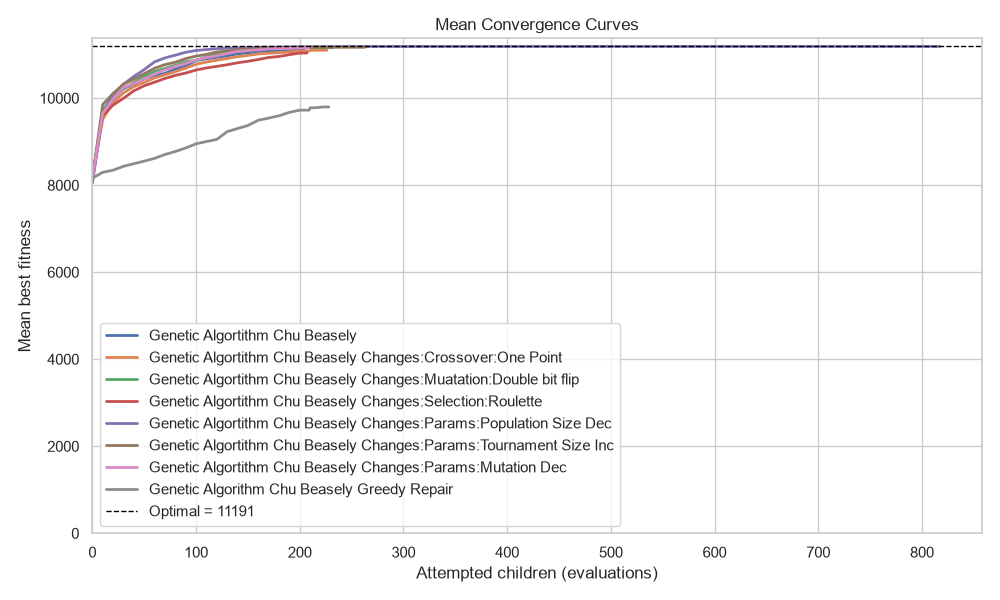

In [124]:
plot_ga_convergence(analysis_chu,optimal_fitness = best_optimal_fitness, y_floor_fraction=0)

The main reasoning behind choosing chu & beaselies paper was that it is proven literature for such problem solution it performs really well actually for a problem like this it is overkill because the termination criteria had to be significantly decreased just to see the changes alteration done on top of the algorithm produce one finding from this is that for relatively smaller problems with this algorithm the best change relatively would be reducing the population becuase it always has to hit the successful evaluation point and even though the diversification of the values is decreased by alot the selection criteria tournament with small tournament size already diversifies it so it can explore in the available area. Realistically the main reason was the relevancy to the problem the aspects that are similar are the following it was designed for a multidimensional knapsack problem, as the name says it was designed to handle multidimensional constraints, its reapair mechanism improves feasibility and is diverse enough all in all it is relevant and provides a standard for experimentation the other options like binary ddifferential evolution which generates new children by combining difference is for continuos problem that would mean additional overhead of changing it to binary values the other algorithms like PSO also uses continuos values like position and velocity again mapping it to binary system is additional overhead

#### Part 3: Experimentation and Analysis

Mementic Genetic Algorithms: The idea is that it follow the same logic as our above solution but before the replacement strategy it optimizes the solution making it even better the ADD logic is already a smaller version of a mementic algorithm but what if we compound it with a hill climbing algorithm with a certain strategy if just the add mementic characteristic showed so much improvement as we saw on our graph what if it is compounded? Does the fitness increase overall for the algorithm or does it become less diversified and converges? What about the more compuation overhead does it play a part is it insignificant

Hypothosis: My hypothosis is that due to imporovement of our value at each step the final fitness will be higher and it will be higher throughout the steps it wont converge. I imagine that the duplicates will increase so number of evaluations will increase over the period and because of the additonal computation it will take more time

Hill Climbing addition: The choice ill chose to bring over is the hill climbing for one bit greedy repair algorithm because it has least compuational cost as we are attaching this to the end of already a compuatational expensive oepration i dont want it to compound too much